# 01 · 一次模型请求，怎样才算成功？

我们给一个虚构的小团队做资料助手。现在手里有：**一个真实模型账号、一份设备借用说明、一个需要依据规则回答的问题**。还没有 HTTP 服务、自动检索或云部署，这些随后逐个加入。

你已经学过 messages 和模型输入输出。这次直接从请求进入工程判断：**HTTP 200、文字生成完成、答案符合事实，是三件不同的事。**

分三段做，每段约 20–30 分钟：① 两次真实请求与观察；② 故障定位和一个小函数；③ 用量、费用与面试解释。接通过 API 的话，第一段快速留下记录即可。

材料是人工编写的；回答由实际模型生成；故障练习另行标注。课件不预先规定模型一定答错，也不把人工回答作为真实结果。


当前 Python： /Users/yorkchen/文稿 - 陈尧的MacBook Pro/VibeCoding/llm-from-zero/.venv/bin/python


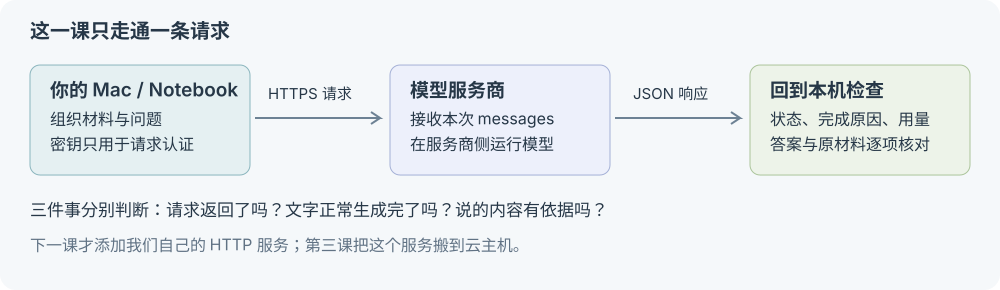

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, SVG

# 支持从项目根目录、新路线目录或本课目录启动。
here = Path.cwd().resolve()
candidates = [here, here / "01-api-observation", here / "cloud-ai-interview" / "01-api-observation"]
COURSE = next((p for p in candidates if (p / "api_lab.py").is_file()), None)
if COURSE is None:
    raise RuntimeError("请在项目根目录、cloud-ai-interview 或本课目录运行。")
sys.path.insert(0, str(COURSE))
from api_lab import configure, build_payload, request_once, show_record, teaching_cost

print("当前 Python：", sys.executable)
display(SVG(filename=str(COURSE / "assets/request-flow.svg")))
# 重跑准备格不清空已记录的尝试；重启内核仍会丢失内存记录。
attempts = globals().get("attempts", [])


## A · 先接通，然后看请求到底带了什么

我们的问题是：“云杉团队的便携显示器最多能借几天？到期还想用，是否可以直接继续用？”

先不给模型那份规则，再只改变一个条件——把规则一起放进请求。模型在第一种情况下可能追问、拒绝猜测，也可能猜一个天数。即使碰巧猜对，仍要看它有没有可靠依据。

先配置已有账号。`RUN_LIVE=False` 时不会读取密钥或发请求；准备好实际运行再改成 `True`。配置本身不请求，下面标出的两个调用格各发送一次。重跑会再次请求，没有自动重试。

DeepSeek 可先用默认 `MODEL=None`。TokenHub 则在 `MODEL` 填你已开通的 **DeepSeek 系列模型 ID**，比如控制台中确实可用的 `deepseek/deepseek-flash`；广州与新加坡密钥不互通。完整说明见本课 README。


In [2]:
RUN_LIVE = False
PROVIDER = "deepseek"   # 或 "tokenhub"
MODEL = "deepseek-flash"           # TokenHub 必须填账号已开通的模型 ID
REGION = "guangzhou"   # TokenHub 可选 "singapore"

config = configure(PROVIDER, MODEL, REGION) if RUN_LIVE else None
print(config if config else "未启用真实调用；没有读取密钥，也不会生成替代回答。")


未启用真实调用；没有读取密钥，也不会生成替代回答。


**先准备两份请求，再比较它们。** 文件现在只是你的 Mac 上的一份文字，模型不会因为它在同一目录就自动读到。我们必须在请求里加入它。

这里不是完整 RAG：材料仍是我们手工选定的。后面文档变多时，才加入“自动找材料”这一步。


In [3]:
rules = (COURSE / "data/device-loan.md").read_text(encoding="utf-8")
question = "云杉团队的便携显示器最多能借几天？到期还想用，是否可以直接继续用？"
instruction = "回答用户的问题。材料不足时说明无法确定，不编造团队政策；提供了材料时注明来源编号。请用100字以内回答。"

messages_a = [
    {"role": "system", "content": instruction},
    {"role": "user", "content": question},
]
messages_b = [
    {"role": "system", "content": instruction},
    {"role": "user", "content": f"参考材料：\n{rules}\n\n问题：{question}"},
]
print("原始材料：\n", rules)
print("A 的用户消息：\n", messages_a[-1]["content"])
print("B 的用户消息：\n", messages_b[-1]["content"])


原始材料：
 # 云杉团队设备借用规则

来源编号：DEV-01
版本：2026-11-01
性质：人工编写的教学材料，不是真实公司的政策。

团队的便携显示器可借用最多 7 个自然日。到期仍需要使用时，应在到期前向设备管理员提交续借申请；提交申请不等于已经批准。

发现设备损坏，应停止继续借给他人，在工单系统中登记设备编号和故障现象，由设备管理员处理。

本文没有规定设备丢失的赔偿金额，也没有授权助手代替管理员批准续借。

A 的用户消息：
 云杉团队的便携显示器最多能借几天？到期还想用，是否可以直接继续用？
B 的用户消息：
 参考材料：
# 云杉团队设备借用规则

来源编号：DEV-01
版本：2026-11-01
性质：人工编写的教学材料，不是真实公司的政策。

团队的便携显示器可借用最多 7 个自然日。到期仍需要使用时，应在到期前向设备管理员提交续借申请；提交申请不等于已经批准。

发现设备损坏，应停止继续借给他人，在工单系统中登记设备编号和故障现象，由设备管理员处理。

本文没有规定设备丢失的赔偿金额，也没有授权助手代替管理员批准续借。


问题：云杉团队的便携显示器最多能借几天？到期还想用，是否可以直接继续用？


下面能看到将要发送的 JSON 正文，认证密钥不在这里显示。两次使用同一模型、关闭思考、非流式、输出上限 512 tokens。`temperature=0` 也不承诺每次完全相同。

`max_tokens` 限制这一次的输出长度；它不等于整次请求的费用上限，也不控制输入长度。我们只发这份很短的教学材料。


In [4]:
preview_model = config.model if config else (MODEL or "deepseek-flash")
print("请求正文预览；没有发送：")
print(json.dumps(build_payload(messages_b, preview_model), ensure_ascii=False, indent=2))


请求正文预览；没有发送：
{
  "model": "deepseek-flash",
  "messages": [
    {
      "role": "system",
      "content": "回答用户的问题。材料不足时说明无法确定，不编造团队政策；提供了材料时注明来源编号。请用100字以内回答。"
    },
    {
      "role": "user",
      "content": "参考材料：\n# 云杉团队设备借用规则\n\n来源编号：DEV-01\n版本：2026-11-01\n性质：人工编写的教学材料，不是真实公司的政策。\n\n团队的便携显示器可借用最多 7 个自然日。到期仍需要使用时，应在到期前向设备管理员提交续借申请；提交申请不等于已经批准。\n\n发现设备损坏，应停止继续借给他人，在工单系统中登记设备编号和故障现象，由设备管理员处理。\n\n本文没有规定设备丢失的赔偿金额，也没有授权助手代替管理员批准续借。\n\n\n问题：云杉团队的便携显示器最多能借几天？到期还想用，是否可以直接继续用？"
    }
  ],
  "thinking": {
    "type": "disabled"
  },
  "temperature": 0,
  "max_tokens": 512,
  "stream": false
}


**真实请求 1 / 2：不给材料。** `request_once()` 把刚才的正文通过 HTTPS 发出，并留下状态和用量。它的发送部分就是 `Request(...)` 与 `urlopen(...)`；其他辅助代码负责配置、异常和展示，本课不要求一次读完整个文件。

如果失败，先停在这里看状态，按后面 C 段的线索检查。不要连续重跑猜原因。


In [5]:
without_context = None
with_context = None   # 重跑 A 后，使旧 B 失效，避免把不同轮次混着比较。
if RUN_LIVE and config is not None:
    without_context = request_once(config, messages_a)
    attempts.append({"experiment": "without_context", **without_context})
    show_record(without_context, "A · 无材料的真实请求")
else:
    print("未发送 A。准备调用时，先修改配置格并重新运行它。")


未发送 A。准备调用时，先修改配置格并重新运行它。


**真实请求 2 / 2：给相同问题加上材料。** A 未取得有效响应时，这格先不继续请求；修复后从 A 重新开始。

观察结果时，先找“7 个自然日”“到期前提交申请”“提交不等于批准”这三点，再核对引用是否对应 DEV-01。引用格式正确也不能替代事实检查。


In [6]:
if RUN_LIVE and config is not None and without_context and without_context["error_kind"] is None:
    with_context = request_once(config, messages_b)
    attempts.append({"experiment": "with_context", **with_context})
    show_record(with_context, "B · 带材料的真实请求")
else:
    print("未发送 B。需要先启用真实调用，并让 A 取得可读取的模型响应。")


未发送 B。需要先启用真实调用，并让 A 取得可读取的模型响应。


## B · 沿这两份记录解释结果

| 检查 | 对应记录 | 能说明什么 | 还不能说明什么 |
|---|---|---|---|
| 收到怎样的响应 | `http_status`、`error_kind` | 请求在客户端观察到的状态 | 200 不证明答案正确 |
| 文本是否正常结束 | `finish_reason`、`content` | 本课中 `stop` 且非空正文是完整性条件 | 正常结束也可能编造内容 |
| 消耗与等待 | `usage`、`elapsed_seconds` | 服务商提供的 token 用量、客户端等了多久 | 不是服务器纯推理时间，也不是首 token 时间 |
| 内容是否有依据 | 对照原材料人工核对 | 本问题的事实和引用是否匹配 | 两个例子不能代表整个系统的准确率 |

`elapsed_seconds` 覆盖从客户端开始发送到读完响应/出错，可能包含网络、排队、推理和接收。把它全称为“模型计算时间”会导致错误排查方向。

**留下自己的观察，不需要写长报告：**

- A 实际怎样回答？它的依据来自哪里？
- B 哪些内容能在原材料中找到？有没有超出材料的结论？
- 我现在能证明什么，仍不能证明什么？

你的记录：

> 待填写，或在讨论中直接说明。

如果两次都正确，照样有结果：说明这一次无材料的回答恰好符合规则，不能推出不需要资料。如果给材料后仍答错，保留原回答；这是后面评测课会用到的问题，不为得到漂亮结果而偷偷换样例。


## C · “失败”究竟发生在哪一层？

下面五份是**人工故障记录**，不访问服务商，不收费，也不混入刚才的真实记录。这样可以稳定练习一些不一定在这两次请求中出现的情况。

切换卡片后先回答：① 已经能确定什么？② 还缺什么信息？③ 下一步做哪一个检查？


In [7]:
fault_cases = [
    {"case": "认证失败", "source": "teaching_fixture", "http_status": 401, "error_kind": "http_error", "finish_reason": None, "content": None, "usage": None},
    {"case": "受到限制", "source": "teaching_fixture", "http_status": 429, "error_kind": "http_error", "finish_reason": None, "content": None, "usage": None},
    {"case": "等待超时", "source": "teaching_fixture", "http_status": None, "error_kind": "timeout", "finish_reason": None, "content": None, "usage": None},
    {"case": "文字未完成", "source": "teaching_fixture", "http_status": 200, "error_kind": None, "finish_reason": "length", "content": "最多可以借用7个自然日，续借需要……", "usage": {"prompt_tokens": 210, "completion_tokens": 20}},
    {"case": "文字完整但事实错", "source": "teaching_fixture", "http_status": 200, "error_kind": None, "finish_reason": "stop", "content": "最多借30天，到期自动批准续借。", "usage": {"prompt_tokens": 210, "completion_tokens": 25}},
]

import ipywidgets as widgets
case_picker = widgets.Dropdown(options=[(c["case"], i) for i, c in enumerate(fault_cases)], description="观察记录：")
case_output = widgets.Output()
def draw_case(change=None):
    with case_output:
        case_output.clear_output(wait=True)
        show_record(fault_cases[case_picker.value], "人工故障样本 · 不是实际调用")
case_picker.observe(draw_case, names="value")
draw_case()
display(widgets.VBox([case_picker, case_output]))


<details><summary>需要时看排查方向</summary>

401 先核对密钥、服务与地域是否匹配；不能仅凭它证明账号没余额。429 看服务商限制说明与额度，并考虑等待和减少并发，不循环轰炸。TokenHub 的未开通/额度问题还可能表现为 402。

超时只说明客户端没等到完成，服务端可能仍在处理；也不能由此断言没有计费。后面有实际写入动作时，这一点会影响能否直接重试。

`length` 表示回答被长度条件终止，应先检查任务和输出上限，不能把截断回答直接交付。`stop` 也无法检查“30 天”是否符合原材料。

这些是排查方向，不是“只要这个状态码就一定是某个原因”。真实失败时继续查看对应服务的错误说明和控制台信息。
</details>

### 把一个判断写进程序

请完成 `text_completed(record)`。它只判断**本课这种非流式纯文字回答**是否完整：HTTP 200、没有记录到错误、结束原因为 `stop`、正文是非空文字。它不判断事实正确，不把 usage 缺失当成生成失败。

需要的 Python 写法：`record.get("content")` 取字段；`isinstance(value, str)` 判断文字；`value.strip()` 去掉首尾空白。先检查类型再调用 `.strip()`，避免对 `None` 调字符串方法。


In [ ]:
def text_completed(record):
    # TODO：返回 True 或 False。保持这个小函数的职责只做“完整性检查”。
    return None


In [ ]:
# 这是课堂函数检查，不发请求，也不是“事实准确率”评测。
expected = [False, False, False, False, True]
actual = [text_completed(item) for item in fault_cases]
if any(value is None for value in actual):
    print("函数尚未完成。可以先说出判断条件，再补代码。")
else:
    assert all(isinstance(value, bool) for value in actual), "请返回 bool。"
    assert actual == expected, list(zip([c["case"] for c in fault_cases], actual, expected))
    empty = {**fault_cases[-1], "content": "   "}
    missing_usage = {**fault_cases[-1], "usage": None}
    assert text_completed(empty) is False, "只有空格的正文不能算完成。"
    assert text_completed(missing_usage) is True, "用量缺失不等于文字没有生成完成。"
    print("完整性检查通过。最后一条事实仍是错的：这一步有意不解决事实核对。")


<details><summary>概念提示</summary>

先区分三道检查：通信、生成完成、事实核对。本函数只覆盖前两道。如果为了让最后那个错误答案返回 False 而把“7天”写死进去，就把两个不同职责混在一起了；而且真实模型可能写“七个自然日”。
</details>

<details><summary>代码组织提示</summary>

可以先取出正文，再按顺序排除错误状态、错误结束原因、非文字和空白正文；剩下的返回 True。也可以把这些条件用 `and` 连接。这里不要求学习新的框架。
</details>

## D · 用量与费用：不知道的部分别填成零

下面只对本次内核保留下来的真实尝试记账。输入假设价 3 元/百万 tokens，输出假设价 9 元/百万 tokens，**不是真实厂商报价**。缓存、失败计费和实际账单需要另外核对。

教学计算：`输入 token × 3 / 1,000,000 + 输出 token × 9 / 1,000,000`。本次 prompt_tokens 已包括发送的材料，不再额外加一遍材料长度。


In [ ]:
known_costs = []
unknown_count = 0
for item in attempts:
    cost = teaching_cost(item)
    print(item["local_request_id"], item["experiment"], "教学假设费用：", "未知" if cost is None else f"{cost:.6f} 元")
    if cost is None:
        unknown_count += 1
    else:
        known_costs.append(cost)

if attempts:
    print(f"已记录 {len(attempts)} 次尝试；已知部分教学费用合计 {sum(known_costs):.6f} 元；用量未知 {unknown_count} 次。")
    print("这不是实付总额；其他内核、其他程序、未记录的失败和此前消费均不在这里。")
else:
    print("没有真实请求记录，无法计算本次用量；不是“花0元完成实验”。")


**一个短估算：** 假设每次请求输入 1200 tokens、输出 300 tokens，每天 100 人，每人 4 次，每月 30 天，用上述教学假设费率，月度模型调用费是多少？另外列出两项这笔钱没包含的成本。如果只有 90% 的任务答对，“每次请求费用”与“每次成功任务费用”是否相同？先说明假设再算。

> 你的假设、计算与未计入项：待填写或口头讨论。

## 离开代码，讲清楚这次实验

用 60–90 秒回答：**“我们接了一个真实模型 API，怎样判断这个接入能不能用于资料问答？”**

用刚才的请求或故障记录举证，不必把术语全说一遍。随后选一个追问：

- 接口都返回 200，但用户投诉答案不对，你先查哪些记录？
- 这次两条答案都对了，为什么还不能宣布系统准确率 100%？
- 云服务器能访问模型 API，为什么用户仍可能访问不到我们的服务？这要到下一课添加哪一层之后才能实际验证？

这次留两份真实记录和一个解释就够了。先讨论你在哪一段仍有疑问，再制作下一课。

下一课从这里继续：把已经会调用、会检查的函数接成 HTTP 服务，让另一个程序能使用它；第三课把同一服务放到云服务器。不会为了上云重新换一个案例。


## 参考与边界

- [DeepSeek 请求响应字段](https://api-docs.deepseek.com/api/create-chat-completion/)
- [TokenHub 语言模型入口](https://cloud.tencent.com/document/product/1823/130079)与[DeepSeek 指南](https://cloud.tencent.com/document/product/1823/132248)
- [课程路线](../ROADMAP.md)与[面试调研](../RESEARCH.md)

接口核对日 2026-11-03。辅助代码没有重试、后台调用或人工回答替代路径。教师用人工通信替身验证程序与 Notebook，不代表已经验证真实模型效果、你的账号或你的独立掌握情况。
